In [4]:
from pathlib import Path
from urllib.request import urlretrieve

data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

url = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2026-05.parquet"

file_path = data_dir / "yellow_tripdata_2026-05.parquet"

if not file_path.exists():
    urlretrieve(url, file_path)

file_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

In [5]:
import pandas as pd

df = pd.read_parquet(file_path)
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-05-01 00:04:59,2026-05-01 00:32:48,1.0,7.51,1.0,N,138,37,2,35.9,6.00,0.5,0.00,0.0,1.0,45.40,0.0,2.0,0.00
1,2,2026-05-01 00:37:05,2026-05-01 00:59:47,1.0,6.14,1.0,N,138,237,1,27.5,6.00,0.5,9.56,0.0,1.0,49.81,2.5,2.0,0.75
2,1,2026-05-01 00:34:05,2026-05-01 00:54:02,1.0,2.40,1.0,N,249,232,1,19.1,4.25,0.5,3.73,0.0,1.0,28.58,2.5,0.0,0.75
3,1,2026-05-01 00:55:07,2026-05-01 01:02:43,0.0,1.20,1.0,N,232,114,1,9.3,4.25,0.5,3.00,0.0,1.0,18.05,2.5,0.0,0.75
4,7,2026-05-01 00:44:13,2026-05-01 00:44:13,2.0,0.86,1.0,N,140,237,1,7.2,0.00,0.5,2.44,0.0,1.0,14.64,2.5,0.0,0.00


In [6]:
df.shape

(4090836, 20)

In [7]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag                  str
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

In [8]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
)

df["duration"] = df["duration"].dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

In [9]:
initial_count = len(df)

df = df[(df["duration"] >= 1) & (df["duration"] <= 60)].copy()

df.shape

(3883752, 21)

In [10]:
len(df) / initial_count * 100

94.93785622303118

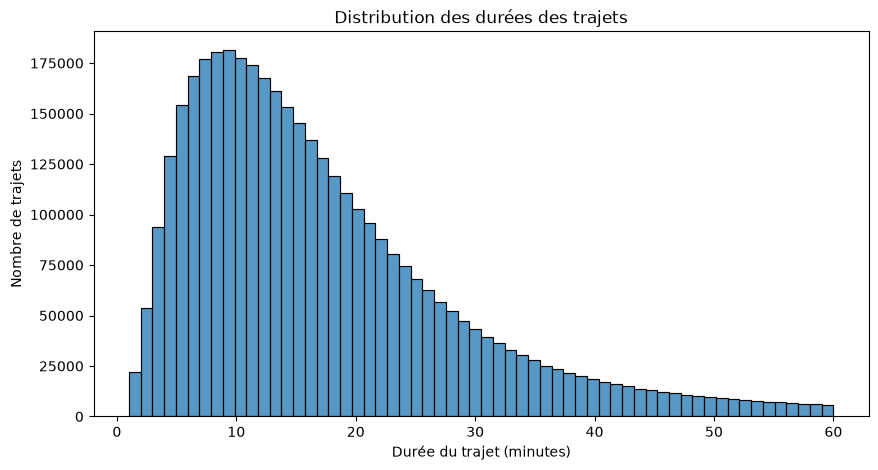

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(df["duration"], bins=60)
plt.xlabel("Durée du trajet (minutes)")
plt.ylabel("Nombre de trajets")
plt.title("Distribution des durées des trajets")
plt.show()

In [12]:
categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)

df[categorical + numerical].head()

,PULocationID,DOLocationID,trip_distance
0,138,37,7.51
1,138,237,6.14
2,249,232,2.40
3,232,114,1.20
5,255,236,5.89


In [13]:
X = df[categorical + numerical]
y = df["duration"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (3883752, 3)
Dimensions de y : (3883752,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [15]:
print("X_train :", X_train.shape)
print("X_val :", X_val.shape)
print("y_train :", y_train.shape)
print("y_val :", y_val.shape)

X_train : (3107001, 3)
X_val : (776751, 3)
y_train : (3107001,)
y_val : (776751,)


In [ ]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer()

train_dicts = X_train.to_dict(orient="records")
val_dicts = X_val.to_dict(orient="records")

X_train_encoded = dv.fit_transform(train_dicts)
X_val_encoded = dv.transform(val_dicts)

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train_encoded, y_train)

In [ ]:
y_pred_lr = lr.predict(X_val_encoded)

y_pred_lr[:10]


In [ ]:
from sklearn.metrics import root_mean_squared_error

rmse_lr = root_mean_squared_error(y_val, y_pred_lr)

print("RMSE Régression linéaire :", rmse_lr)

In [ ]:
import numpy as np
from sklearn.linear_model import Lasso

X_train_encoded = X_train_encoded.tocsc()
X_val_encoded = X_val_encoded.tocsc()

X_train_encoded.indices = X_train_encoded.indices.astype(np.int32)
X_train_encoded.indptr = X_train_encoded.indptr.astype(np.int32)

X_val_encoded.indices = X_val_encoded.indices.astype(np.int32)
X_val_encoded.indptr = X_val_encoded.indptr.astype(np.int32)

lasso = Lasso(alpha=0.01)
lasso.fit(X_train_encoded, y_train)

In [ ]:
y_pred_lasso = lasso.predict(X_val_encoded)

y_pred_lasso[:10]

In [ ]:
rmse_lasso = root_mean_squared_error(y_val, y_pred_lasso)

print("RMSE Lasso :", rmse_lasso)

In [ ]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=2,
    tree_method="hist"
)

xgb_model.fit(X_train_encoded, y_train)

In [ ]:
y_pred_xgb = xgb_model.predict(X_val_encoded)

y_pred_xgb[:10]

In [ ]:
rmse_xgb = root_mean_squared_error(y_val, y_pred_xgb)

print("RMSE XGBoost :", rmse_xgb)

In [ ]:
results = pd.DataFrame({
    "Modèle": ["Régression linéaire", "Lasso", "XGBoost"],
    "RMSE": [rmse_lr, rmse_lasso, rmse_xgb]
})

results.sort_values("RMSE")

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(data=results, x="Modèle", y="RMSE")

plt.title("Comparaison des performances des modèles")
plt.ylabel("RMSE (minutes)")
plt.xlabel("Modèle")

plt.show()

In [ ]:
best_model = results.loc[results["RMSE"].idxmin()]

print("Meilleur modèle :", best_model["Modèle"])
print("RMSE :", best_model["RMSE"], "minutes")

In [ ]:
print("Conclusion du TP")

print(f"Régression linéaire : {rmse_lr:.2f} minutes")
print(f"Lasso : {rmse_lasso:.2f} minutes")
print(f"XGBoost : {rmse_xgb:.2f} minutes")

print(f"Le modèle le plus performant est {best_model['Modèle']}")
print(f"Son RMSE est de {best_model['RMSE']:.2f} minutes.")